Data Preparation and Feature Engineering

In [1]:
import sys
%pip install -q yfinance pandas numpy matplotlib seaborn scikit-learn scipy openpyxl pyarrow lxml html5lib
print("Python", sys.version)

Python 3.13.18 (main, Oct 26 2026, 15:28:15) [GCC 13.3.0]


In [2]:
import sys
import json
import warnings
from datetime import datetime, timezone
from pathlib import Path
from IPython.display import display

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 140)

START = "2021-01-01"
END_EXCLUSIVE = "2025-01-01"   # exclusive, as the brief says
BENCHMARK = "^GSPC"
WIKI_URL = "https://en.wikipedia.org/wiki/List_of_S%26P_500_companies"

ROOT = Path(".")
DATA_DIR = ROOT / "data"
OUT_DIR = ROOT / "outputs"
for p in (DATA_DIR, OUT_DIR):
    p.mkdir(parents=True, exist_ok=True)

print("Run started (UTC):", datetime.now(timezone.utc).isoformat())
print("Library: yfinance. Reason: seminar notebooks use it and it returns Close, Adj Close and Volume together.")

Run started (UTC): 2026-11-21T05:38:33.114247+00:00
Library: yfinance. Reason: seminar notebooks use it and it returns Close, Adj Close and Volume together.


Task 1.1 Wikipedia Tickers

In [3]:
from datetime import datetime, timezone

wiki_retrieved_utc = datetime.now(timezone.utc)
wiki_tables = pd.read_html(
    WIKI_URL,
    storage_options={"User-Agent": "Mozilla/5.0 (Coursework 6BUIS017W)"},
)
sp500_meta = wiki_tables[0].copy()
sp500_meta.columns = [str(c).strip() for c in sp500_meta.columns]

# Yahoo uses '-' where Wikipedia uses '.'  e.g. BRK.B -> BRK-B
sp500_meta["YahooTicker"] = sp500_meta["Symbol"].astype(str).str.replace(".", "-", regex=False)
tickers = sp500_meta["YahooTicker"].tolist()

print("Wikipedia retrieval (UTC):", wiki_retrieved_utc.isoformat())
print("Constituents extracted:", len(tickers))
display(sp500_meta[["Symbol", "Security", "GICS Sector"]].head(10))
sp500_meta.to_csv(DATA_DIR / "sp500_constituents.csv", index=False)

Wikipedia retrieval (UTC): 2026-11-21T05:38:33.143270+00:00
Constituents extracted: 503


,Symbol,Security,GICS Sector
0,MMM,3M,Industrials
1,AOS,A. O. Smith,Industrials
2,ABT,Abbott Laboratories,Health Care
3,ABBV,AbbVie,Health Care
4,ACN,Accenture,Information Technology
5,ADBE,Adobe Inc.,Information Technology
6,AMD,Advanced Micro Devices,Information Technology
7,AES,AES Corporation,Utilities
8,AFL,Aflac,Financials
9,A,Agilent Technologies,Health Care


In [4]:
import yfinance as yf

cache_path = DATA_DIR / "sp500_daily_ohlcv.parquet"

def flatten_yf(raw):
    if not isinstance(raw.columns, pd.MultiIndex):
        return raw
    lvl0 = [str(x) for x in raw.columns.get_level_values(0)]
    if any(x in lvl0 for x in ("Adj Close", "Close", "Volume")):
        return raw
    return raw.swaplevel(0, 1, axis=1).sort_index(axis=1)

if cache_path.exists():
    print("Loading cached file")
    daily = pd.read_parquet(cache_path)
else:
    print("Downloading from Yahoo Finance...")
    raw = yf.download(
        tickers + [BENCHMARK],
        start=START,
        end=END_EXCLUSIVE,
        auto_adjust=False,
        group_by="column",
        threads=True,
        progress=True,
    )
    daily = flatten_yf(raw)
    daily.to_parquet(cache_path)
    print("Saved cache to", cache_path)

print("Shape:", daily.shape)
print("Date range:", daily.index.min(), "to", daily.index.max())

[*********************100%***********************]  504 of 504 completed
ERROR:yfinance:
5 Failed downloads:
ERROR:yfinance:['HONA', 'VYLR', 'SNDK', 'FDXF', 'Q']: YFPricesMissingError('possibly delisted; no price data found  (1d 2021-01-01 -> 2025-01-01) (Yahoo error = "Data doesn\'t exist for startDate = 1609477200, endDate = 1735707600")')


Saved cache to data/sp500_daily_ohlcv.parquet
Shape: (1005, 3024)
Date range: 2021-01-04 00:00:00 to 2024-12-31 00:00:00


Split Close, Adj Close, Volume

In [5]:
def panel(field):
    if isinstance(daily.columns, pd.MultiIndex):
        if field in daily.columns.get_level_values(0):
            out = daily[field].copy()
        else:
            out = daily.xs(field, axis=1, level=1).copy()
    else:
        out = daily[[field]].copy()
    out.index = pd.to_datetime(out.index)
    keep = [c for c in out.columns if c in set(tickers + [BENCHMARK])]
    return out[keep].sort_index()

close = panel("Close")
adj = panel("Adj Close")
volume = panel("Volume")

market_adj = adj[BENCHMARK].rename("AdjClose")
share_tickers = [t for t in tickers if t in adj.columns and t != BENCHMARK]

print("Shares downloaded:", len(share_tickers))
print("Benchmark days:", market_adj.dropna().shape[0])
print("First date:", adj.index.min().date(), "Last date:", adj.index.max().date())

Shares downloaded: 503
Benchmark days: 1005
First date: 2021-01-04 Last date: 2024-12-31


Task 1.2 Validation

In [6]:
exclusion_rows = []

def exclude(ticker, reason):
    exclusion_rows.append({"Ticker": ticker, "Reason": reason})

print("Duplicate dates:", adj.index.duplicated().sum())

trading_days = market_adj.dropna().index
print("Benchmark trading days:", len(trading_days))

adj_s = adj.reindex(trading_days)[share_tickers]
close_s = close.reindex(trading_days)[share_tickers]
vol_s = volume.reindex(trading_days)[share_tickers]

n_days = len(trading_days)
min_history = int(0.90 * n_days)
print("Minimum history (90% of benchmark days):", min_history)

valid_tickers = []
for t in share_tickers:
    a, c, v = adj_s[t], close_s[t], vol_s[t]
    if a.isna().all():
        exclude(t, "No Adj Close data")
        continue
    if (a.dropna() <= 0).any() or (c.dropna() <= 0).any():
        exclude(t, "Non-positive price")
        continue
    if (v.dropna() < 0).any():
        exclude(t, "Negative volume")
        continue
    if a.notna().sum() < min_history:
        exclude(t, f"Unequal history: {int(a.notna().sum())} of {n_days} days")
        continue
    first, last = a.first_valid_index(), a.last_valid_index()
    if a.loc[first:last].isna().any() or c.loc[first:last].isna().any() or v.loc[first:last].isna().any():
        exclude(t, "Interior missing prices/volume (not filled)")
        continue
    valid_tickers.append(t)

print("Retained shares:", len(valid_tickers))
print("Excluded shares:", len(exclusion_rows))
exclusion_log = pd.DataFrame(exclusion_rows)
display(exclusion_log["Reason"].value_counts().to_frame("count") if len(exclusion_log) else "No exclusions")
exclusion_log.to_csv(OUT_DIR / "exclusion_log.csv", index=False)

adj_v = adj_s[valid_tickers]
close_v = close_s[valid_tickers]
vol_v = vol_s[valid_tickers]

ratio = (close_v / adj_v).replace([np.inf, -np.inf], np.nan)
ratio_range = (ratio.max() - ratio.min()).sort_values(ascending=False)
print("Shares with changing Close/AdjClose (splits or dividends likely):", int((ratio_range > 1e-8).sum()))
display(ratio_range.head(10).to_frame("close_adj_range"))
print("Use Adj Close for weekly return and beta. Use Close * Volume for Monetary.")

Duplicate dates: 0
Benchmark trading days: 1005
Minimum history (90% of benchmark days): 904
Retained shares: 491
Excluded shares: 12


,count
Reason,
No Adj Close data,5
Unequal history: 742 of 1005 days,1
Unequal history: 513 of 1005 days,1
Unequal history: 193 of 1005 days,1
Unequal history: 197 of 1005 days,1
Unequal history: 862 of 1005 days,1
Unequal history: 194 of 1005 days,1
Unequal history: 313 of 1005 days,1


Shares with changing Close/AdjClose (splits or dividends likely): 401


,close_adj_range
Ticker,
MO,0.424290
T,0.371770
LYB,0.318200
KMI,0.304992
OKE,0.299866
VZ,0.299120
DVN,0.273014
SPG,0.262341
F,0.255368


Use Adj Close for weekly return and beta. Use Close * Volume for Monetary.


Task 1.3 Friday Weeks

In [7]:
def friday_weeks(price):
    weekly = price.resample("W-FRI").last()
    week_end = weekly.index
    week_start = week_end - pd.Timedelta(days=6)
    study_start = pd.Timestamp(START)
    study_last = pd.Timestamp(END_EXCLUSIVE) - pd.Timedelta(days=1)
    keep = (week_start >= study_start) & (week_end <= study_last)
    return weekly.loc[keep]

weekly_adj = friday_weeks(adj_v)
weekly_mkt = friday_weeks(market_adj).squeeze()

common_weeks = weekly_adj.index.intersection(weekly_mkt.index)
weekly_adj = weekly_adj.loc[common_weeks]
weekly_mkt = weekly_mkt.loc[common_weeks]

share_ret = weekly_adj.pct_change(fill_method=None)
mkt_ret = weekly_mkt.pct_change(fill_method=None).rename("market")

print("Complete Friday weeks kept:", len(common_weeks))
print("First week:", common_weeks.min().date(), "Last week:", common_weeks.max().date())

Complete Friday weeks kept: 208
First week: 2021-01-08 Last week: 2024-12-27


Task 1.3 Mean Weekly Return and Weekly Beta

In [8]:
risk_rows = []
for t in valid_tickers:
    paired = pd.concat(
        [share_ret[t].rename("share"), mkt_ret],
        axis=1,
    ).replace([np.inf, -np.inf], np.nan).dropna()
    n = len(paired)
    var_m = paired["market"].var(ddof=1)
    mean_r = paired["share"].mean()
    beta = paired["share"].cov(paired["market"]) / var_m if n >= 2 and var_m > 0 else np.nan
    risk_rows.append({
        "Share": t,
        "MeanWeeklyReturn": mean_r,
        "WeeklyBeta": beta,
        "AlignedWeeks": n,
    })

risk_df = pd.DataFrame(risk_rows).set_index("Share")
print("Aligned weekly observations (benchmark):", int(mkt_ret.dropna().shape[0]))
display(risk_df["AlignedWeeks"].describe().to_frame())
display(risk_df.head(10))
risk_df.to_csv(OUT_DIR / "weekly_return_beta.csv")

Aligned weekly observations (benchmark): 207


,AlignedWeeks
count,491.000000
mean,206.932790
std,0.920051
min,193.000000
25%,207.000000
50%,207.000000
75%,207.000000
max,207.000000


,MeanWeeklyReturn,WeeklyBeta,AlignedWeeks
Share,,,
MMM,0.001142,0.869078,207
AOS,0.001991,1.042804,207
ABT,0.000971,0.583543,207
ABBV,0.003749,0.425366,207
ACN,0.002376,1.143301,207
ADBE,0.000990,1.553525,207
AMD,0.003624,1.877622,207
AES,-0.001420,1.143912,207
AFL,0.005004,0.707197,207


Task 1.4 Recency, Frequency, Monetary

In [9]:
obs_date = trading_days[-1]
print("Observation date:", obs_date.date())

rfm_rows = []
rfm_exclude = []

for t in valid_tickers:
    v = vol_v[t].dropna()
    c = close_v[t].reindex(v.index)

    if v.index[-1] != obs_date:
        rfm_exclude.append((t, "Last volume date is not the observation date"))
        continue
    if len(v) < 80:
        rfm_exclude.append((t, "Not enough history for 20-day baseline and 60-day window"))
        continue

    prev20_mean = v.shift(1).rolling(20).mean()          # excludes today
    high = v > (2.0 * prev20_mean)
    valid_flag = prev20_mean.notna()
    flagged = high & valid_flag

    freq = int(flagged.iloc[-60:].sum())
    monetary = float((c.iloc[-60:] * v.iloc[-60:]).sum())

    events = flagged[flagged]
    if events.empty:
        recency = pd.NA
        rfm_exclude.append((t, "No high-volume day found; Recency missing, drop from RFM clustering"))
    else:
        recency = (obs_date.date() - events.index[-1].date()).days

    rfm_rows.append({
        "Share": t,
        "ObservationDate": obs_date.date(),
        "Recency": recency,
        "Frequency": freq,
        "Monetary": monetary,
        "LastEventDate": events.index[-1].date() if not events.empty else pd.NA,
    })

rfm_df = pd.DataFrame(rfm_rows).set_index("Share")
rfm_df["Recency"] = rfm_df["Recency"].astype("Int64")
print("RFM rows:", len(rfm_df))
print("Missing Recency:", int(rfm_df["Recency"].isna().sum()))
display(rfm_df.head(10))
rfm_df.to_csv(OUT_DIR / "rfm_features.csv")

if rfm_exclude:
    extra = pd.DataFrame(rfm_exclude, columns=["Ticker", "Reason"])
    exclusion_log = pd.concat([exclusion_log, extra], ignore_index=True)
    exclusion_log.to_csv(OUT_DIR / "exclusion_log.csv", index=False)
    print("Extra RFM exclusions:", len(extra))

Observation date: 2024-12-31
RFM rows: 491
Missing Recency: 0


,ObservationDate,Recency,Frequency,Monetary,LastEventDate
Share,,,,,
MMM,2024-12-31,11,4,2.599146e+10,2024-12-20
AOS,2024-12-31,11,2,4.748980e+09,2024-12-20
ABT,2024-12-31,11,1,3.523027e+10,2024-12-20
ABBV,2024-12-31,11,3,6.837054e+10,2024-12-20
ACN,2024-12-31,11,2,5.199430e+10,2024-12-20
ADBE,2024-12-31,18,3,1.030403e+11,2024-12-13
AMD,2024-12-31,18,4,3.131659e+11,2024-12-13
AES,2024-12-31,54,3,1.119578e+10,2024-11-07
AFL,2024-12-31,11,2,1.328456e+10,2024-12-20


Task 1.4/1.5

In [10]:
example_ticker = "AAPL" if "AAPL" in rfm_df.index else rfm_df.index[0]
v = vol_v[example_ticker].dropna()
c = close_v[example_ticker].reindex(v.index)
prev20_mean = v.shift(1).rolling(20).mean()
threshold = 2.0 * prev20_mean
high = v > threshold
valid_flag = prev20_mean.notna()

last60 = pd.DataFrame({
    "Close": c.iloc[-60:],
    "Volume": v.iloc[-60:],
    "Prev20MeanVolume": prev20_mean.iloc[-60:],
    "Threshold_2x": threshold.iloc[-60:],
    "HighVolume": (high & valid_flag).iloc[-60:],
    "TradedValue_USD": c.iloc[-60:] * v.iloc[-60:],
})
last60.index.name = "Date"

row = rfm_df.loc[example_ticker]
print("Example share:", example_ticker)
print("Observation date:", obs_date.date())
print("Recency (calendar days):", row["Recency"])
print("Last event date:", row["LastEventDate"])
print("Frequency:", row["Frequency"])
print("Monetary USD:", f"{row['Monetary']:,.2f}")
print("Check Frequency =", int(last60["HighVolume"].sum()))
print("Check Monetary =", f"{last60['TradedValue_USD'].sum():,.2f}")
display(last60)
last60.to_csv(OUT_DIR / f"worked_example_{example_ticker}.csv")

Example share: AAPL
Observation date: 2024-12-31
Recency (calendar days): 11
Last event date: 2024-12-20
Frequency: 2
Monetary USD: 623,303,377,706.58
Check Frequency = 2
Check Monetary = 623,303,377,706.58


,Close,Volume,Prev20MeanVolume,Threshold_2x,HighVolume,TradedValue_USD
Date,,,,,,
2024-10-07,221.690002,39505400,61024170.0,122048340.0,False,8.757952e+09
2024-10-08,225.770004,31855700,59640440.0,119280880.0,False,7.192062e+09
2024-10-09,229.539993,33591100,58653675.0,117307350.0,False,7.710501e+09
2024-10-10,229.039993,28183500,58103875.0,116207750.0,False,6.455149e+09
2024-10-11,227.550003,31759200,57640270.0,115280540.0,False,7.226806e+09
2024-10-14,231.300003,39882100,57389900.0,114779800.0,False,9.224730e+09
2024-10-15,233.850006,64751400,56416135.0,112832270.0,False,1.514212e+10
2024-10-16,231.779999,34082200,57377740.0,114755480.0,False,7.899572e+09
2024-10-17,232.149994,32993800,56087105.0,112174210.0,False,7.659510e+09


Task 2 - Clustering libraries and folders

In [11]:
from pathlib import Path
from scipy.cluster.hierarchy import linkage, dendrogram
from scipy.stats import skew
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering
from sklearn.metrics import silhouette_score, adjusted_rand_score
from sklearn.decomposition import PCA

RANDOM_STATE = 42
N_INIT = 10
K_RANGE = range(2, 9)

FIG_DIR = Path("outputs") / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)
print("Ready for Task 2")

Ready for Task 2


Task 2.1 Two Matrices, log1p(M), standardise

In [12]:
features = risk_df.join(
    rfm_df[["Recency", "Frequency", "Monetary", "ObservationDate"]],
    how="inner",
)
features = features.replace([np.inf, -np.inf], np.nan)
features = features.dropna(
    subset=["MeanWeeklyReturn", "WeeklyBeta", "Recency", "Frequency", "Monetary"]
).copy()
features["Recency"] = features["Recency"].astype(float)
features["log1p_Monetary"] = np.log1p(features["Monetary"])

sector_map = sp500_meta.set_index("YahooTicker")["GICS Sector"]
name_map = sp500_meta.set_index("YahooTicker")["Security"]
features["Sector"] = features.index.map(sector_map)
features["Security"] = features.index.map(name_map)

print("Common shares for all four clustering solutions:", len(features))

rr_cols = ["MeanWeeklyReturn", "WeeklyBeta"]
rfm_cols_raw = ["Recency", "Frequency", "Monetary"]
rfm_cols = ["Recency", "Frequency", "log1p_Monetary"]

print("\nSkew:")
for col in rr_cols + rfm_cols_raw + ["log1p_Monetary"]:
    print(f"  {col:20s} skew={skew(features[col].to_numpy(), nan_policy='omit'): .3f}")

scaler_rr = StandardScaler()
scaler_rfm = StandardScaler()
X_rr = scaler_rr.fit_transform(features[rr_cols])
X_rfm = scaler_rfm.fit_transform(features[rfm_cols])

def outlier_report(X, cols, label):
    z = pd.DataFrame(X, index=features.index, columns=cols)
    print(f"{label}: shares with any |z|>3:", int((z.abs() > 3).any(axis=1).sum()))
    return z

z_rr = outlier_report(X_rr, rr_cols, "Risk-return")
z_rfm = outlier_report(X_rfm, rfm_cols, "RFM")
features.to_csv(OUT_DIR / "feature_table_common_shares.csv")

Common shares for all four clustering solutions: 491

Skew:
  MeanWeeklyReturn     skew= 0.939
  WeeklyBeta           skew= 1.253
  Recency              skew= 3.629
  Frequency            skew= 0.419
  Monetary             skew= 11.626
  log1p_Monetary       skew= 1.072
Risk-return: shares with any |z|>3: 9
RFM: shares with any |z|>3: 22


Task 2.1 Histograms

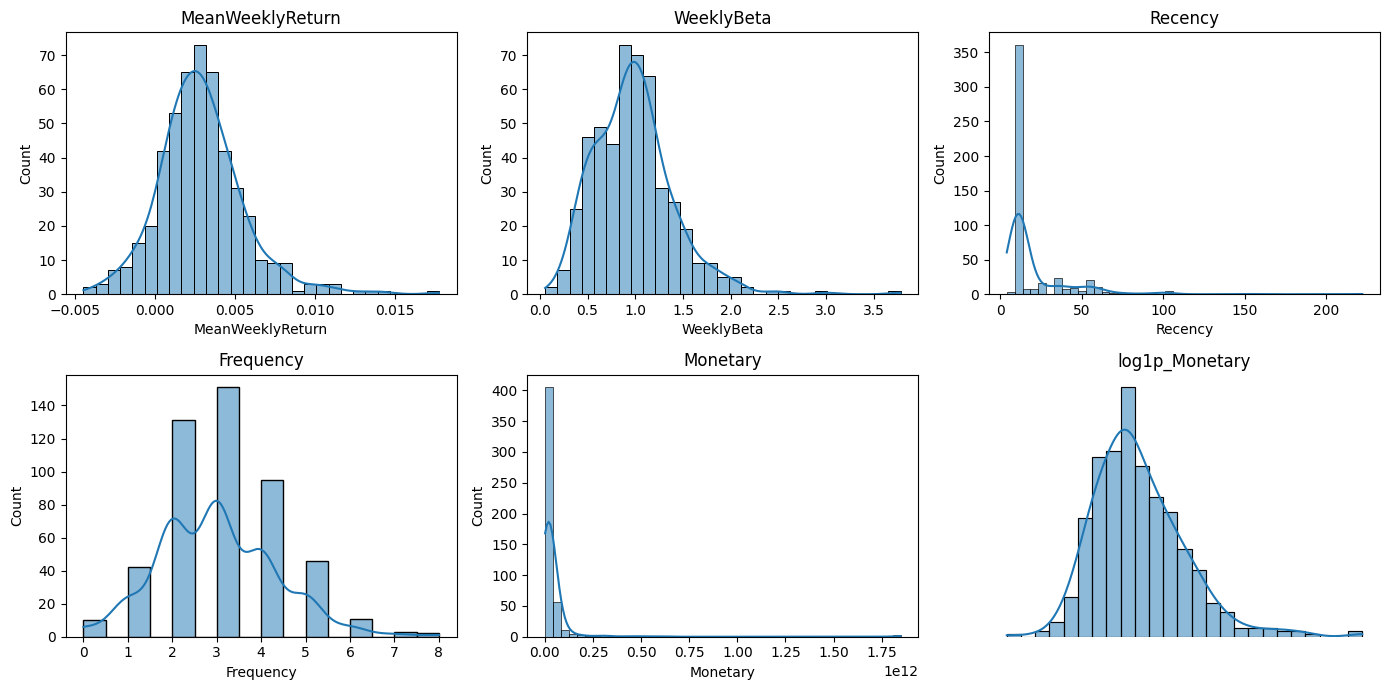

In [13]:
fig, axes = plt.subplots(2, 3, figsize=(14, 7))
plot_cols = rr_cols + ["Recency", "Frequency", "Monetary", "log1p_Monetary"]
for ax, col in zip(axes.ravel(), plot_cols):
    sns.histplot(features[col], ax=ax, kde=True)
    ax.set_title(col)
axes.ravel()[-1].axis("off")
plt.tight_layout()
plt.savefig(FIG_DIR / "feature_distributions.png", dpi=150)
plt.show()

Task 2.2 Ward Dendograms and k = 2 to 8

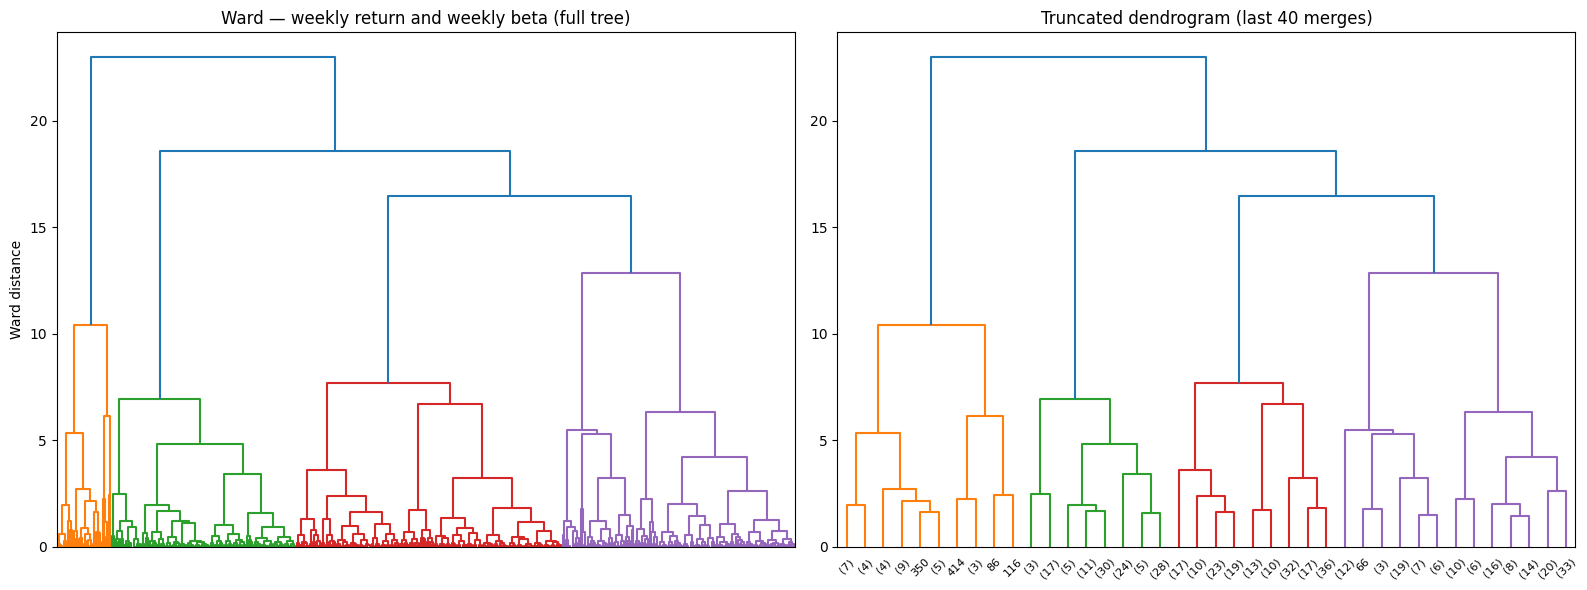

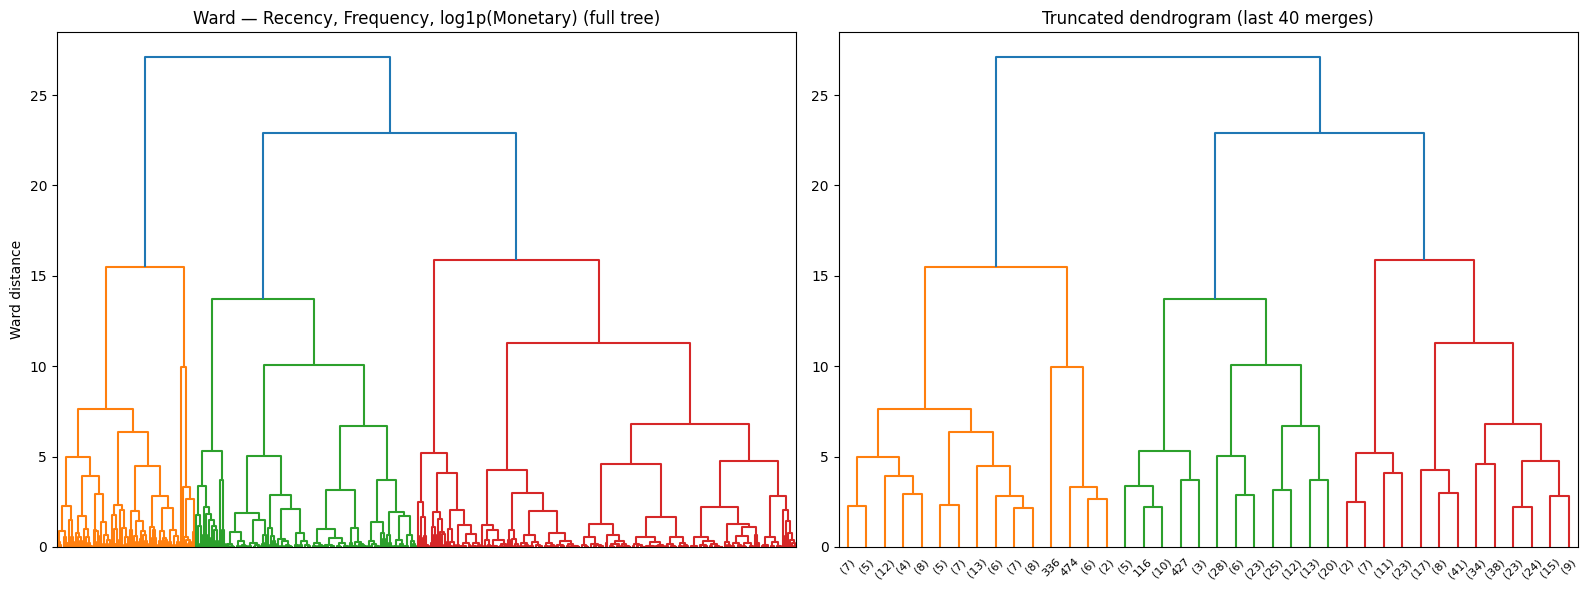

Risk-return diagnostics


,ward_silhouette,ward_min_size,ward_max_size,kmeans_silhouette,kmeans_inertia,kmeans_min_size,kmeans_max_size
k,,,,,,,
2,0.511,36,455,0.389,627.141,146,345
3,0.264,36,332,0.321,473.601,121,204
4,0.296,36,177,0.323,373.915,37,175
5,0.324,36,177,0.335,315.986,30,168
6,0.328,6,177,0.335,261.350,7,154
7,0.295,6,123,0.341,226.587,7,146
8,0.293,6,108,0.355,192.952,7,140


RFM diagnostics


,ward_silhouette,ward_min_size,ward_max_size,kmeans_silhouette,kmeans_inertia,kmeans_min_size,kmeans_max_size
k,,,,,,,
2,0.359,92,399,0.424,1079.102,69,422
3,0.307,92,252,0.325,807.181,63,275
4,0.293,43,209,0.341,616.031,61,215
5,0.312,10,209,0.358,520.538,11,201
6,0.320,10,209,0.346,440.963,11,143
7,0.298,10,143,0.348,391.651,1,144
8,0.305,10,143,0.348,346.357,1,142


In [14]:
def evaluate_k(X, k_range=K_RANGE, random_state=RANDOM_STATE):
    rows = []
    for k in k_range:
        lab_w = AgglomerativeClustering(n_clusters=k, linkage="ward").fit_predict(X)
        km = KMeans(n_clusters=k, random_state=random_state, n_init=N_INIT)
        lab_k = km.fit_predict(X)
        sizes_w = np.bincount(lab_w)
        sizes_k = np.bincount(lab_k)
        rows.append({
            "k": k,
            "ward_silhouette": silhouette_score(X, lab_w),
            "ward_min_size": int(sizes_w.min()),
            "ward_max_size": int(sizes_w.max()),
            "kmeans_silhouette": silhouette_score(X, lab_k),
            "kmeans_inertia": float(km.inertia_),
            "kmeans_min_size": int(sizes_k.min()),
            "kmeans_max_size": int(sizes_k.max()),
        })
    return pd.DataFrame(rows).set_index("k")

def plot_dendrogram(Z, title, path, p=40):
    fig, axes = plt.subplots(1, 2, figsize=(16, 6))
    dendrogram(Z, ax=axes[0], no_labels=True, color_threshold=None)
    axes[0].set_title(title + " (full tree)")
    axes[0].set_ylabel("Ward distance")
    dendrogram(Z, ax=axes[1], truncate_mode="lastp", p=p, show_leaf_counts=True)
    axes[1].set_title(f"Truncated dendrogram (last {p} merges)")
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()

Z_rr = linkage(X_rr, method="ward")
Z_rfm = linkage(X_rfm, method="ward")
plot_dendrogram(Z_rr, "Ward — weekly return and weekly beta", FIG_DIR / "dendrogram_risk_return.png")
plot_dendrogram(Z_rfm, "Ward — Recency, Frequency, log1p(Monetary)", FIG_DIR / "dendrogram_rfm.png")

diag_rr = evaluate_k(X_rr)
diag_rfm = evaluate_k(X_rfm)
print("Risk-return diagnostics")
display(diag_rr.round(3))
print("RFM diagnostics")
display(diag_rfm.round(3))
diag_rr.to_csv(OUT_DIR / "diagnostics_risk_return.csv")
diag_rfm.to_csv(OUT_DIR / "diagnostics_rfm.csv")

In [15]:
def choose_k(diag, prefer="ward_silhouette"):
    size_col = "ward_min_size" if "ward" in prefer else "kmeans_min_size"
    ranked = diag.sort_values(prefer, ascending=False)
    screened = ranked[ranked[size_col] >= 10]
    return int((screened if len(screened) else ranked).index[0])

K_RR_WARD = choose_k(diag_rr, "ward_silhouette")
K_RFM_WARD = choose_k(diag_rfm, "ward_silhouette")
K_RR_KM = choose_k(diag_rr, "kmeans_silhouette")
K_RFM_KM = choose_k(diag_rfm, "kmeans_silhouette")

print("Selected k:")
print("  Ward risk-return:", K_RR_WARD)
print("  Ward RFM:        ", K_RFM_WARD)
print("  K-means risk-return:", K_RR_KM)
print("  K-means RFM:        ", K_RFM_KM)

# After you look at silhouette, sizes and dendrograms, you can force values, e.g.:
# K_RR_WARD, K_RFM_WARD, K_RR_KM, K_RFM_KM = 3, 4, 3, 4

Selected k:
  Ward risk-return: 2
  Ward RFM:         2
  K-means risk-return: 2
  K-means RFM:         2


Task 2.3 K - means elbow and silhouette plots

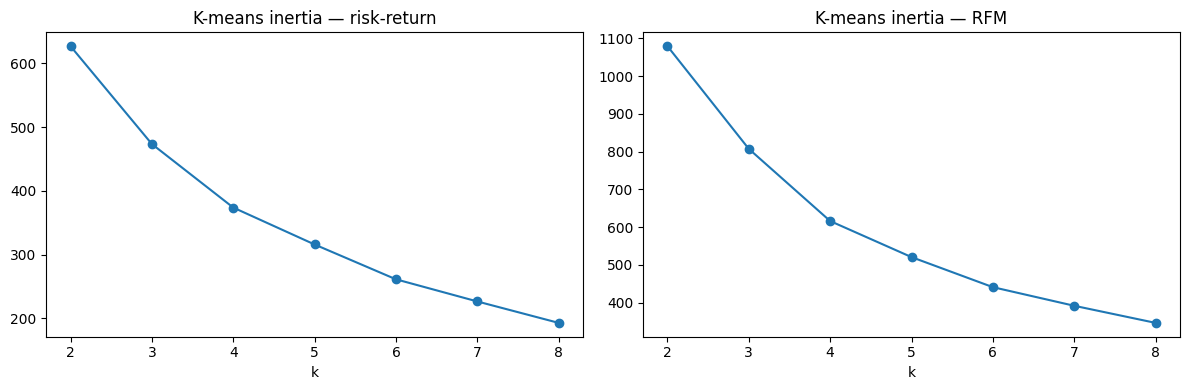

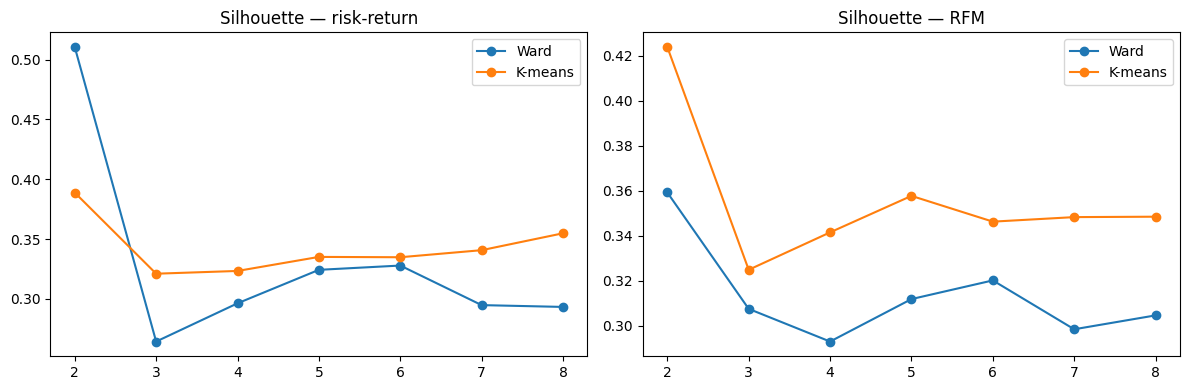

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(diag_rr.index, diag_rr["kmeans_inertia"], marker="o")
axes[0].set_title("K-means inertia — risk-return")
axes[0].set_xlabel("k")
axes[1].plot(diag_rfm.index, diag_rfm["kmeans_inertia"], marker="o")
axes[1].set_title("K-means inertia — RFM")
axes[1].set_xlabel("k")
plt.tight_layout()
plt.savefig(FIG_DIR / "kmeans_elbow.png", dpi=150)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(diag_rr.index, diag_rr["ward_silhouette"], marker="o", label="Ward")
axes[0].plot(diag_rr.index, diag_rr["kmeans_silhouette"], marker="o", label="K-means")
axes[0].set_title("Silhouette — risk-return")
axes[0].legend()
axes[1].plot(diag_rfm.index, diag_rfm["ward_silhouette"], marker="o", label="Ward")
axes[1].plot(diag_rfm.index, diag_rfm["kmeans_silhouette"], marker="o", label="K-means")
axes[1].set_title("Silhouette — RFM")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "silhouette_scores.png", dpi=150)
plt.show()

Four baseline clusterings

In [17]:
features["Ward_RR"] = AgglomerativeClustering(n_clusters=K_RR_WARD, linkage="ward").fit_predict(X_rr)
features["KMeans_RR"] = KMeans(n_clusters=K_RR_KM, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(X_rr)
features["Ward_RFM"] = AgglomerativeClustering(n_clusters=K_RFM_WARD, linkage="ward").fit_predict(X_rfm)
features["KMeans_RFM"] = KMeans(n_clusters=K_RFM_KM, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(X_rfm)

print("Adjusted Rand index (same shares; labels can be swapped):")
print("  Ward vs K-means | risk-return:", round(adjusted_rand_score(features["Ward_RR"], features["KMeans_RR"]), 3))
print("  Ward vs K-means | RFM:        ", round(adjusted_rand_score(features["Ward_RFM"], features["KMeans_RFM"]), 3))
print("  Ward RR vs Ward RFM:          ", round(adjusted_rand_score(features["Ward_RR"], features["Ward_RFM"]), 3))

Adjusted Rand index (same shares; labels can be swapped):
  Ward vs K-means | risk-return: 0.21
  Ward vs K-means | RFM:         0.739
  Ward RR vs Ward RFM:           0.027


Task 2.4 Original-unit profiles

In [18]:
def profile(df, cluster_col, value_cols):
    return df.groupby(cluster_col)[value_cols].agg(["mean", "median", "std", "count"])

print("Ward risk-return")
display(profile(features, "Ward_RR", rr_cols))
print("K-means risk-return")
display(profile(features, "KMeans_RR", rr_cols))
print("Ward RFM (Monetary in USD, not log)")
display(profile(features, "Ward_RFM", rfm_cols_raw))
print("K-means RFM")
display(profile(features, "KMeans_RFM", rfm_cols_raw))

profile(features, "Ward_RR", rr_cols).to_csv(OUT_DIR / "profile_ward_rr.csv")
profile(features, "KMeans_RR", rr_cols).to_csv(OUT_DIR / "profile_kmeans_rr.csv")
profile(features, "Ward_RFM", rfm_cols_raw).to_csv(OUT_DIR / "profile_ward_rfm.csv")
profile(features, "KMeans_RFM", rfm_cols_raw).to_csv(OUT_DIR / "profile_kmeans_rfm.csv")

Ward risk-return


MeanWeeklyReturn                           WeeklyBeta                          
                    mean    median       std count       mean    median       std count
Ward_RR                                                                                
0               0.002411  0.002527  0.002040   455   0.938128  0.931355  0.369874   455
1               0.009021  0.008024  0.002514    36   1.518936  1.444517  0.618297    36

K-means risk-return


MeanWeeklyReturn                           WeeklyBeta                          
                      mean    median       std count       mean    median       std count
KMeans_RR                                                                                
0                 0.001832  0.001921  0.001817   345   0.817762  0.840680  0.295670   345
1                 0.005408  0.004908  0.002780   146   1.365768  1.278197  0.422337   146

Ward RFM (Monetary in USD, not log)


Recency                         Frequency                             Monetary                                  
               mean median        std count      mean median       std count          mean        median           std count
Ward_RFM                                                                                                                    
0         12.328321   11.0   5.270566   399  3.210526    3.0  1.276297   399  3.835661e+10  1.548218e+10  1.107021e+11   399
1         55.586957   53.0  27.935228    92  2.054348    2.0  1.132576    92  4.569727e+10  2.048974e+10  1.887968e+11    92

K-means RFM


Recency                         Frequency                             Monetary                                  
                 mean median        std count      mean median       std count          mean        median           std count
KMeans_RFM                                                                                                                    
0           13.450237   11.0   6.995155   422  3.187204    3.0  1.256065   422  3.271447e+10  1.556962e+10  6.107016e+10   422
1           63.144928   55.0  28.418757    69  1.811594    2.0  1.141147    69  8.265111e+10  2.274797e+10  3.069559e+11    69

2.4 Labelled plots

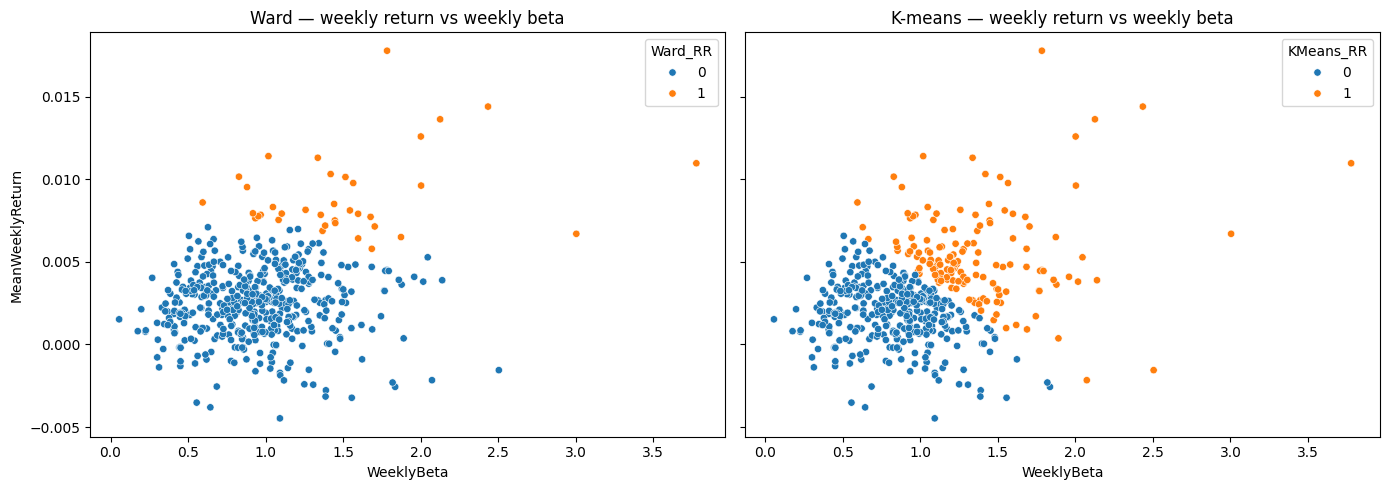

RFM PCA variance explained: [0.456 0.339] sum 0.795


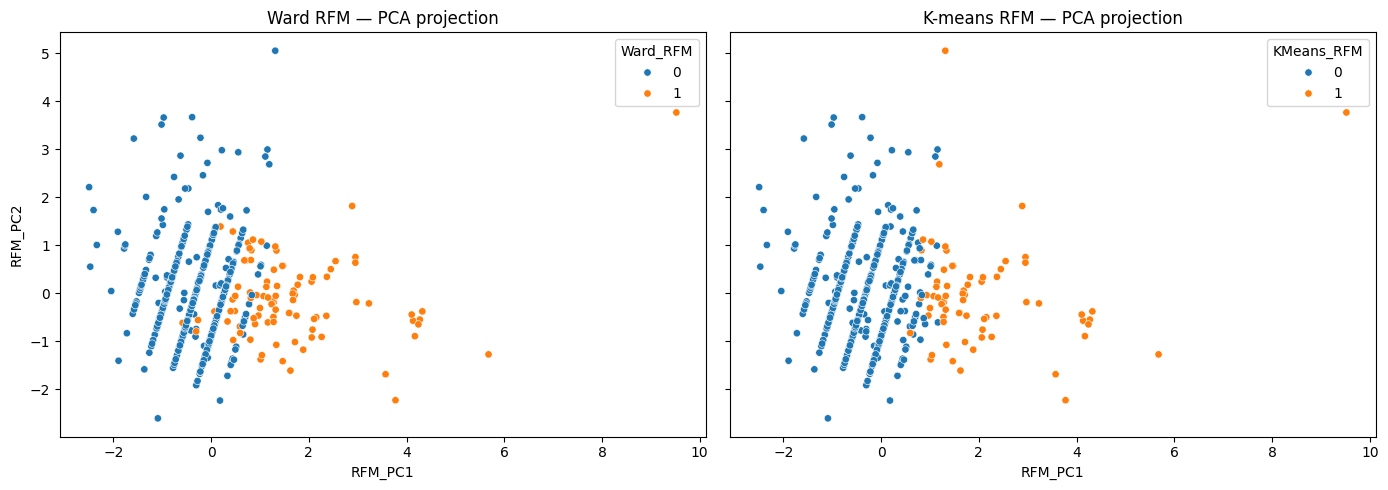

PCA is a picture only. Clusters were fitted on the three standardised RFM features, not on 2D PCA.


In [19]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, col, title in [
    (axes[0], "Ward_RR", "Ward — weekly return vs weekly beta"),
    (axes[1], "KMeans_RR", "K-means — weekly return vs weekly beta"),
]:
    sns.scatterplot(data=features, x="WeeklyBeta", y="MeanWeeklyReturn", hue=col, palette="tab10", ax=ax, s=28)
    ax.set_title(title)
plt.tight_layout()
plt.savefig(FIG_DIR / "scatter_risk_return_clusters.png", dpi=150)
plt.show()

pca = PCA(n_components=2, random_state=RANDOM_STATE)
pcs = pca.fit_transform(X_rfm)
features["RFM_PC1"] = pcs[:, 0]
features["RFM_PC2"] = pcs[:, 1]
print("RFM PCA variance explained:", pca.explained_variance_ratio_.round(3),
      "sum", round(pca.explained_variance_ratio_.sum(), 3))

fig, axes = plt.subplots(1, 2, figsize=(14, 5), sharex=True, sharey=True)
for ax, col, title in [
    (axes[0], "Ward_RFM", "Ward RFM — PCA projection"),
    (axes[1], "KMeans_RFM", "K-means RFM — PCA projection"),
]:
    sns.scatterplot(data=features, x="RFM_PC1", y="RFM_PC2", hue=col, palette="tab10", ax=ax, s=28)
    ax.set_title(title)
plt.tight_layout()
plt.savefig(FIG_DIR / "scatter_rfm_pca_clusters.png", dpi=150)
plt.show()
print("PCA is a picture only. Clusters were fitted on the three standardised RFM features, not on 2D PCA.")

Task 2.5.1 RFM Correlations

,Recency,Frequency,log1p_Monetary
Recency,1.000,-0.342,0.159
Frequency,-0.342,1.000,0.022
log1p_Monetary,0.159,0.022,1.000


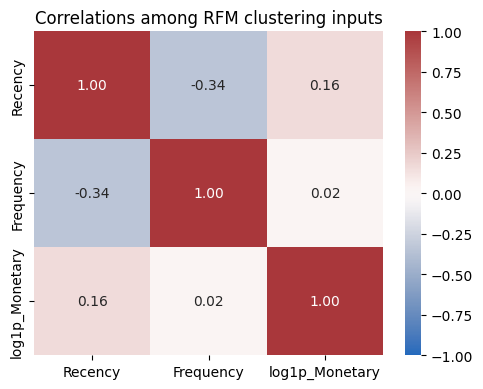

In [20]:
corr = features[["Recency", "Frequency", "log1p_Monetary"]].corr()
display(corr.round(3))
corr.to_csv(OUT_DIR / "rfm_correlations.csv")

plt.figure(figsize=(5, 4))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="vlag", vmin=-1, vmax=1)
plt.title("Correlations among RFM clustering inputs")
plt.tight_layout()
plt.savefig(FIG_DIR / "rfm_correlation_heatmap.png", dpi=150)
plt.show()

Task 2.5.2 Remove Monetary, same k, ARI

In [21]:
scaler_rf = StandardScaler()
X_rf = scaler_rf.fit_transform(features[["Recency", "Frequency"]])
features["Ward_RF_noM"] = AgglomerativeClustering(
    n_clusters=K_RFM_WARD, linkage="ward"
).fit_predict(X_rf)

ari = adjusted_rand_score(features["Ward_RFM"], features["Ward_RF_noM"])
print("Selected Ward RFM k:", K_RFM_WARD)
print("ARI, full RFM vs Recency+Frequency only:", round(ari, 3))
print("1 = same grouping (numbers may differ). 0 = no better than chance.")

print("\nMonetary by full RFM Ward clusters")
display(features.groupby("Ward_RFM")["Monetary"].agg(["mean", "median", "count"]).round(2))
print("Monetary by R+F only Ward clusters")
display(features.groupby("Ward_RF_noM")["Monetary"].agg(["mean", "median", "count"]).round(2))

ct = pd.crosstab(features["Ward_RFM"], features["Ward_RF_noM"], margins=True)
display(ct)
ct.to_csv(OUT_DIR / "crosstab_rfm_vs_no_monetary.csv")
features.to_csv(OUT_DIR / "cluster_assignments.csv")
print("Saved outputs/cluster_assignments.csv")

Selected Ward RFM k: 2
ARI, full RFM vs Recency+Frequency only: 0.952
1 = same grouping (numbers may differ). 0 = no better than chance.

Monetary by full RFM Ward clusters


,mean,median,count
Ward_RFM,,,
0,3.835661e+10,1.548218e+10,399
1,4.569727e+10,2.048974e+10,92


Monetary by R+F only Ward clusters


,mean,median,count
Ward_RF_noM,,,
0,3.782930e+10,1.546039e+10,400
1,4.809577e+10,2.084781e+10,91


Ward_RF_noM,0,1,All
Ward_RFM,,,
0,397,2,399
1,3,89,92
All,400,91,491


Saved outputs/cluster_assignments.csv


Sector Mix

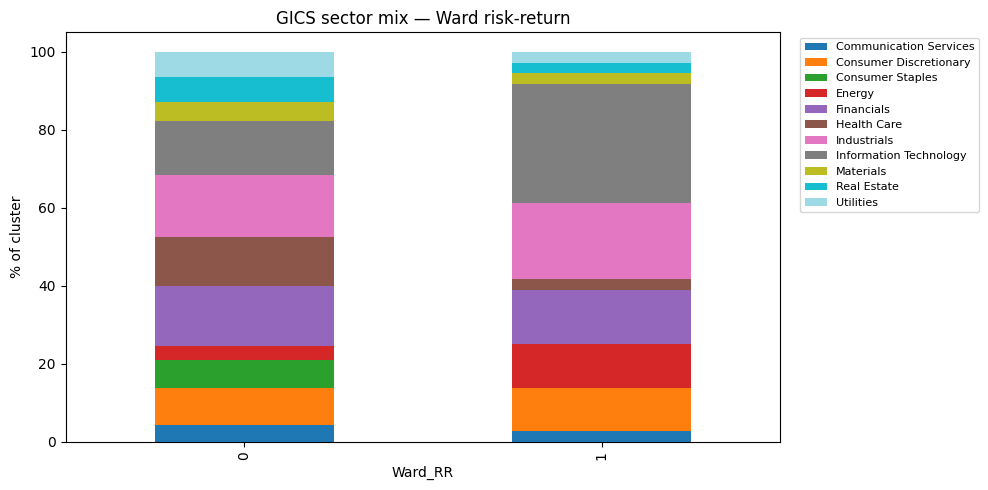

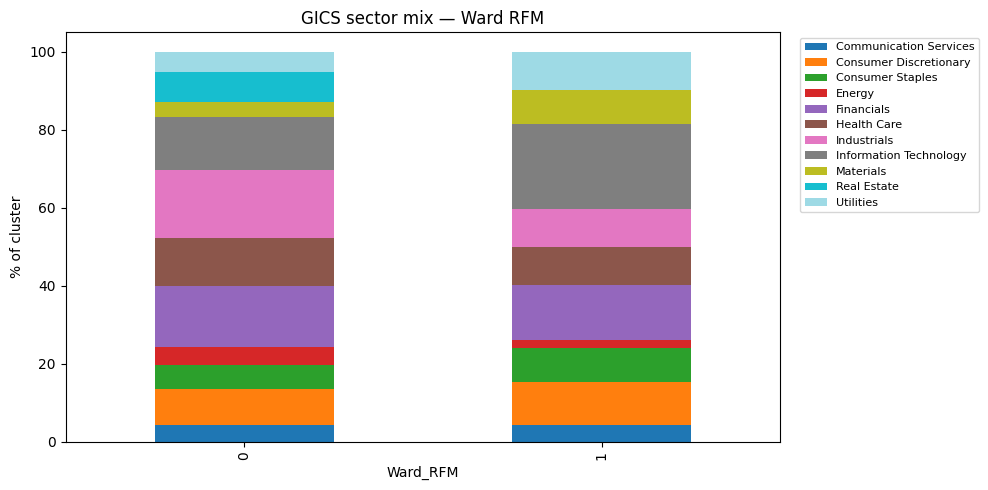

Crosstab Ward risk-return vs Ward RFM


Ward_RFM,0,1,All
Ward_RR,,,
0,372,83,455
1,27,9,36
All,399,92,491


ARI Ward RR vs Ward RFM: 0.027


In [22]:
def sector_plot(cluster_col, path, title):
    tab = pd.crosstab(features[cluster_col], features["Sector"], normalize="index") * 100
    ax = tab.plot(kind="bar", stacked=True, figsize=(10, 5), colormap="tab20")
    ax.set_ylabel("% of cluster")
    ax.set_title(title)
    ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", fontsize=8)
    plt.tight_layout()
    plt.savefig(path, dpi=150)
    plt.show()
    return tab

tab_rr = sector_plot("Ward_RR", FIG_DIR / "sector_ward_rr.png", "GICS sector mix — Ward risk-return")
tab_rfm = sector_plot("Ward_RFM", FIG_DIR / "sector_ward_rfm.png", "GICS sector mix — Ward RFM")
tab_rr.to_csv(OUT_DIR / "sector_mix_ward_rr.csv")
tab_rfm.to_csv(OUT_DIR / "sector_mix_ward_rfm.csv")

print("Crosstab Ward risk-return vs Ward RFM")
ct2 = pd.crosstab(features["Ward_RR"], features["Ward_RFM"], margins=True)
display(ct2)
ct2.to_csv(OUT_DIR / "crosstab_rr_vs_rfm.csv")
print("ARI Ward RR vs Ward RFM:", round(adjusted_rand_score(features["Ward_RR"], features["Ward_RFM"]), 3))

In [23]:
from scipy.cluster.hierarchy import cophenet
from scipy.spatial.distance import pdist
from scipy.stats import kruskal, spearmanr

# ===== S1: Task 1.5 feature summary (fills the [insert ...] placeholders) =====
num_cols = ["MeanWeeklyReturn", "WeeklyBeta", "Recency", "Frequency", "Monetary"]
summ = features[num_cols].agg(["min", "median", "mean", "max"]).T
summ["skew"] = [skew(features[c]) for c in num_cols]
display(summ.round(4))
summ.to_csv(OUT_DIR / "feature_summary_task1.csv")

# ===== S2: extra evidence for 2.2 and 2.3 =====
for name, Z, X, kw, kk in [("Risk-return", Z_rr, X_rr, K_RR_WARD, K_RR_KM),
                           ("RFM", Z_rfm, X_rfm, K_RFM_WARD, K_RFM_KM)]:
    coph = cophenet(Z, pdist(X))[0]
    print(f"\n{name}: Ward cophenetic correlation = {coph:.3f}; top 6 merge heights = {np.round(Z[-6:, 2][::-1], 2)}")
    aris, singles = [], []
    for s in range(20):
        lab = KMeans(n_clusters=kk, random_state=s, n_init=N_INIT).fit_predict(X)
        aris.append(adjusted_rand_score(lab, KMeans(n_clusters=kk, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(X)))
        singles.append(KMeans(n_clusters=kk, random_state=s, n_init=1).fit(X).inertia_)
    print(f"{name}: K-means k={kk}, ARI vs seed-42 solution over 20 seeds: min={min(aris):.3f}, mean={np.mean(aris):.3f}")
    print(f"{name}: single-start inertia range over 20 seeds: {min(singles):.1f} to {max(singles):.1f}")

# ===== S3: extra evidence for 2.5.1 and 2.5.2 =====
def eta2(v, lab):
    gm = v.mean()
    return sum(len(g) * (g.mean() - gm) ** 2 for _, g in v.groupby(lab)) / ((v - gm) ** 2).sum()

pca3 = PCA().fit(X_rfm)
print("\nPCA variance shares (RFM):", pca3.explained_variance_ratio_.round(3), "| equal weighting would be 0.333 each")
print("Spearman R-F, R-M, F-M:",
      round(spearmanr(features.Recency, features.Frequency)[0], 3),
      round(spearmanr(features.Recency, features.Monetary)[0], 3),
      round(spearmanr(features.Frequency, features.Monetary)[0], 3))
lm = features["log1p_Monetary"]
print("Share of log1p(M) variance explained by groups: full RFM =", round(eta2(lm, features["Ward_RFM"]), 3),
      "| R,F only =", round(eta2(lm, features["Ward_RF_noM"]), 3))
for col in ["Ward_RFM", "Ward_RF_noM"]:
    H, p = kruskal(*[g.values for _, g in lm.groupby(features[col])])
    print(f"Kruskal-Wallis on log1p(M) across {col}: H={H:.2f}, p={p:.3g}")
display(features.groupby("Ward_RF_noM")[["Recency", "Frequency"]].median())

a, b = features["Ward_RFM"], features["Ward_RF_noM"]
b_al = b if (a != b).sum() <= (a == b).sum() else 1 - b   # align arbitrary 0/1 labels (k = 2)
print("Shares whose group differs between the two solutions:", list(features.index[a != b_al]))

,min,median,mean,max,skew
MeanWeeklyReturn,-4.500000e-03,2.700000e-03,2.900000e-03,1.780000e-02,0.9389
WeeklyBeta,5.550000e-02,9.532000e-01,9.807000e-01,3.778600e+00,1.2533
Recency,4.000000e+00,1.100000e+01,2.043380e+01,2.220000e+02,3.6286
Frequency,0.000000e+00,3.000000e+00,2.993900e+00,8.000000e+00,0.4188
Monetary,1.297483e+09,1.670905e+10,3.973205e+10,1.847697e+12,11.6258



Risk-return: Ward cophenetic correlation = 0.556; top 6 merge heights = [22.99 18.55 16.44 12.83 10.41  7.67]
Risk-return: K-means k=2, ARI vs seed-42 solution over 20 seeds: min=1.000, mean=1.000
Risk-return: single-start inertia range over 20 seeds: 627.1 to 770.6

RFM: Ward cophenetic correlation = 0.504; top 6 merge heights = [27.11 22.89 15.87 15.51 13.72 11.29]
RFM: K-means k=2, ARI vs seed-42 solution over 20 seeds: min=0.989, mean=0.997
RFM: single-start inertia range over 20 seeds: 1079.1 to 1144.4

PCA variance shares (RFM): [0.456 0.339 0.205] | equal weighting would be 0.333 each
Spearman R-F, R-M, F-M: -0.189 0.147 -0.039
Share of log1p(M) variance explained by groups: full RFM = 0.003 | R,F only = 0.005
Kruskal-Wallis on log1p(M) across Ward_RFM: H=4.01, p=0.0453
Kruskal-Wallis on log1p(M) across Ward_RF_noM: H=5.19, p=0.0227


,Recency,Frequency
Ward_RF_noM,,
0,11.0,3.0
1,53.0,2.0


Shares whose group differs between the two solutions: ['XYZ', 'COIN', 'EFX', 'PPG', 'TKO']


Task 3 - 3.2.1


Ward_RR: sector counts and % of each cluster


Ward_RR,n_cluster_0,n_cluster_1,pct_cluster_0,pct_cluster_1
Sector,,,,
Communication Services,20,1,4.4,2.8
Consumer Discretionary,43,4,9.5,11.1
Consumer Staples,32,0,7.0,0.0
Energy,17,4,3.7,11.1
Financials,70,5,15.4,13.9
Health Care,57,1,12.5,2.8
Industrials,72,7,15.8,19.4
Information Technology,63,11,13.8,30.6
Materials,23,1,5.1,2.8



Ward_RFM: sector counts and % of each cluster


Ward_RFM,n_cluster_0,n_cluster_1,pct_cluster_0,pct_cluster_1
Sector,,,,
Communication Services,17,4,4.3,4.3
Consumer Discretionary,37,10,9.3,10.9
Consumer Staples,24,8,6.0,8.7
Energy,19,2,4.8,2.2
Financials,62,13,15.5,14.1
Health Care,49,9,12.3,9.8
Industrials,70,9,17.5,9.8
Information Technology,54,20,13.5,21.7
Materials,16,8,4.0,8.7


,All shares %
Sector,
Industrials,16.1
Financials,15.3
Information Technology,15.1
Health Care,11.8
Consumer Discretionary,9.6
Consumer Staples,6.5
Utilities,6.1
Real Estate,6.1
Materials,4.9



Full original-unit profile: Ward_RR


... (7 outputs left out)


Ward risk-return (rows) vs Ward RFM (columns): counts, then row %


Ward_RFM,0,1
Ward_RR,,
0,372,83
1,27,9


Ward_RFM,0,1
Ward_RR,,
0,81.8,18.2
1,75.0,25.0


ARI: 0.027


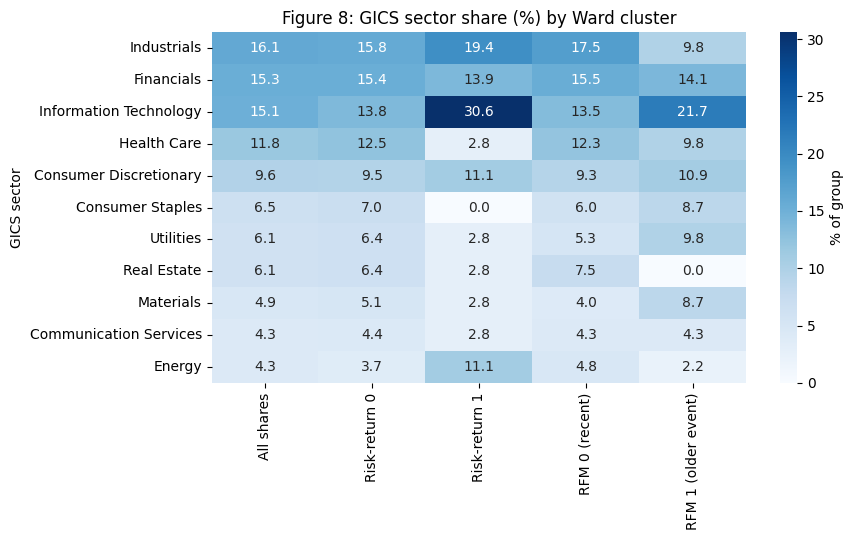

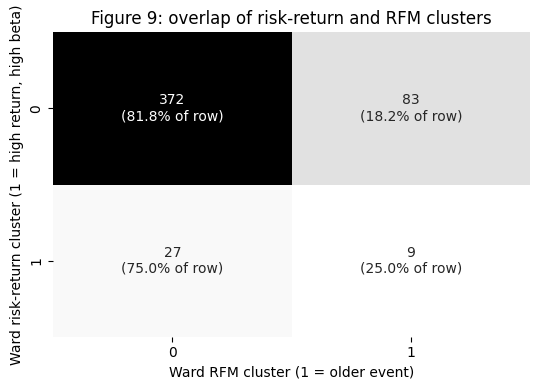

In [24]:
# ===== T3-A: Task 3.2.1 sector composition, full original-unit profiles, overlap figure =====
sector_pct = {}
for col in ["Ward_RR", "Ward_RFM"]:
    counts = pd.crosstab(features["Sector"], features[col])
    pct = (counts / counts.sum() * 100).round(1)
    sector_pct[col] = pct
    out = pd.concat([counts.add_prefix("n_cluster_"), pct.add_prefix("pct_cluster_")], axis=1)
    print(f"\n{col}: sector counts and % of each cluster")
    display(out)
    out.to_csv(OUT_DIR / f"t3_sector_composition_{col}.csv")
overall = (features["Sector"].value_counts(normalize=True) * 100).round(1)
display(overall.rename("All shares %").to_frame())

def full_profile(col):
    g = features.groupby(col)
    return pd.DataFrame({
        "n": g.size(),
        "MeanWeeklyReturn_%": g["MeanWeeklyReturn"].mean() * 100,
        "MeanBeta": g["WeeklyBeta"].mean(),
        "MedianRecency_days": g["Recency"].median(),
        "MeanFrequency": g["Frequency"].mean(),
        "MedianMonetary_$bn": g["Monetary"].median() / 1e9,
    }).round(3)

for col in ["Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM"]:
    print(f"\nFull original-unit profile: {col}")
    display(full_profile(col))
    full_profile(col).to_csv(OUT_DIR / f"t3_full_profile_{col}.csv")

ct = pd.crosstab(features["Ward_RR"], features["Ward_RFM"])
row_pct = (ct.div(ct.sum(axis=1), axis=0) * 100).round(1)
print("\nWard risk-return (rows) vs Ward RFM (columns): counts, then row %")
display(ct); display(row_pct)
print("ARI:", round(adjusted_rand_score(features["Ward_RR"], features["Ward_RFM"]), 3))

# Figure 8: sector share by cluster next to the all-share mix
sectors = overall.index.tolist()
heat = pd.DataFrame({
    "All shares": overall,
    "Risk-return 0": sector_pct["Ward_RR"][0], "Risk-return 1": sector_pct["Ward_RR"][1],
    "RFM 0 (recent)": sector_pct["Ward_RFM"][0], "RFM 1 (older event)": sector_pct["Ward_RFM"][1],
}).reindex(sectors).fillna(0)
fig, ax = plt.subplots(figsize=(9, 5.5))
sns.heatmap(heat, annot=True, fmt=".1f", cmap="Blues", cbar_kws={"label": "% of group"}, ax=ax)
ax.set_title("Figure 8: GICS sector share (%) by Ward cluster")
ax.set_ylabel("GICS sector")
plt.tight_layout(); plt.savefig(FIG_DIR / "t3_sector_heatmap.png", dpi=150); plt.show()

# Figure 9: overlap of the two segmentations
annot = ct.astype(str) + "\n(" + row_pct.astype(str) + "% of row)"
fig, ax = plt.subplots(figsize=(5.5, 4))
sns.heatmap(ct, annot=annot, fmt="", cmap="Greys", cbar=False, ax=ax)
ax.set_xlabel("Ward RFM cluster (1 = older event)"); ax.set_ylabel("Ward risk-return cluster (1 = high return, high beta)")
ax.set_title("Figure 9: overlap of risk-return and RFM clusters")
plt.tight_layout(); plt.savefig(FIG_DIR / "t3_overlap_heatmap.png", dpi=150); plt.show()

Task 3 - B

Package versions (paste into the report): {'yfinance': '0.2.66', 'pandas': '2.2.3', 'numpy': '2.4.6', 'scipy': '1.16.3', 'scikit-learn': '1.6.1', 'matplotlib': '3.10.0', 'seaborn': '0.13.2', 'pyarrow': '23.0.1', 'lxml': '6.1.3', 'python': '3.13.18'}
{'dim_date': 1005, 'dim_share': 503, 'dim_sector': 11, 'dim_benchmark': 1, 'dim_run': 1, 'fact_daily_price': 493290, 'fact_weekly_return': 101604, 'fact_benchmark_daily': 1005, 'fact_share_features': 491, 'fact_cluster_assignment': 2455, 'exclusion_log': 12}
MMM: Monetary from mart = 25,991,458,733.34 | feature table = 25,991,458,733.34 | match = True


,Sector,ClusterLabel,Shares,MeanBeta,MeanWeeklyReturnPct
0,Communication Services,0,20,0.87,0.237
1,Communication Services,1,1,2.43,1.439
2,Consumer Discretionary,0,43,1.15,0.287
3,Consumer Discretionary,1,4,1.95,0.880
4,Consumer Staples,0,32,0.52,0.103
5,Energy,0,17,0.73,0.530
6,Energy,1,4,0.90,0.877
7,Financials,0,70,0.95,0.296
8,Financials,1,5,1.86,0.750
9,Health Care,0,57,0.82,0.112


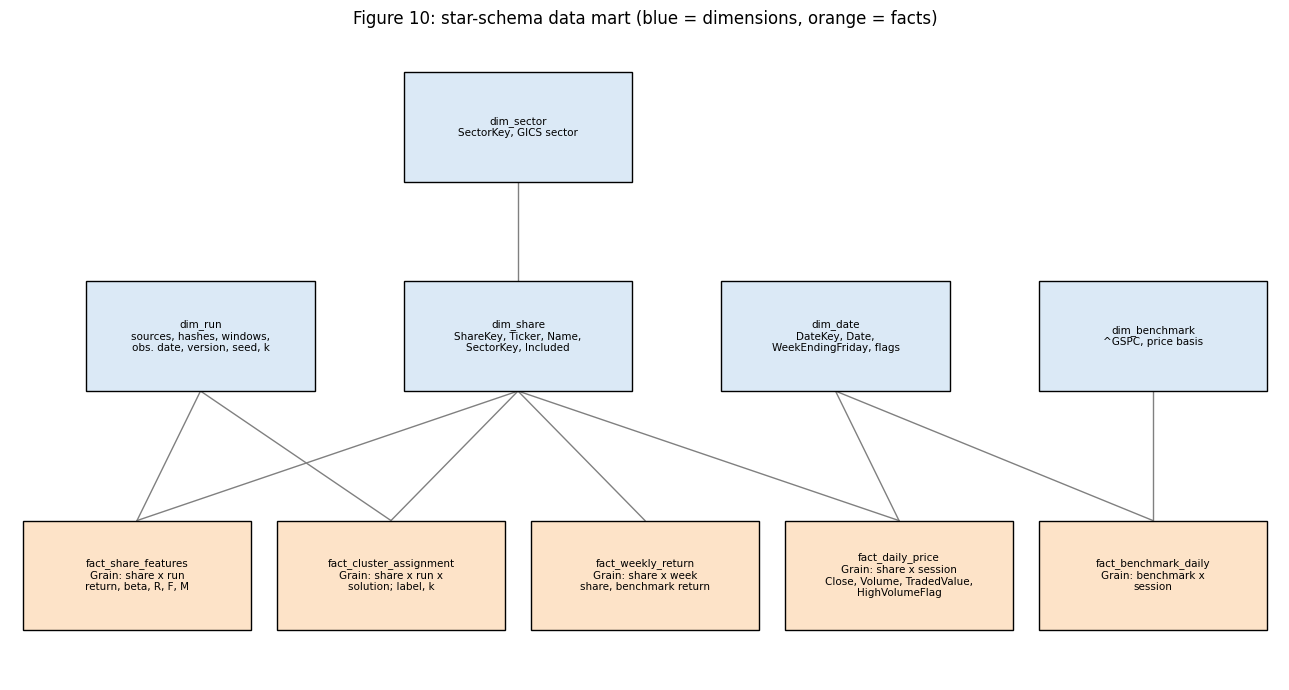

Saved: data/mart/mart.sqlite, parquet tables, outputs/run_metadata.json, figures/t3_data_mart_schema.png


In [25]:
# ===== T3-B: build the star-schema data mart, record versions and run metadata =====
import sqlite3, hashlib, platform, subprocess
import importlib.metadata as md
from matplotlib.patches import Rectangle

MART_DIR = DATA_DIR / "mart"
MART_DIR.mkdir(exist_ok=True)
CALC_VERSION = "v1.0"
RUN_ID = f"{CALC_VERSION}_obs{obs_date.date()}"

def pkg(p):
    try: return md.version(p)
    except Exception: return "n/a"
versions = {p: pkg(p) for p in ["yfinance", "pandas", "numpy", "scipy", "scikit-learn", "matplotlib", "seaborn", "pyarrow", "lxml"]}
versions["python"] = platform.python_version()
print("Package versions (paste into the report):", versions)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as fh:
        for chunk in iter(lambda: fh.read(1 << 20), b""):
            h.update(chunk)
    return h.hexdigest()

try:
    commit = subprocess.check_output(["git", "rev-parse", "--short", "HEAD"], stderr=subprocess.DEVNULL).decode().strip()
except Exception:
    commit = "set after first GitHub commit"

# ---- dimensions ----
dim_sector = pd.DataFrame({"Sector": sorted(sp500_meta["GICS Sector"].dropna().unique())})
dim_sector.insert(0, "SectorKey", np.arange(1, len(dim_sector) + 1))

dim_share = (sp500_meta[["YahooTicker", "Security", "GICS Sector"]]
             .rename(columns={"YahooTicker": "Ticker", "GICS Sector": "Sector"})
             .drop_duplicates("Ticker").reset_index(drop=True))
dim_share.insert(0, "ShareKey", np.arange(1, len(dim_share) + 1))
dim_share["SectorKey"] = dim_share["Sector"].map(dim_sector.set_index("Sector")["SectorKey"])
reasons = exclusion_log.drop_duplicates("Ticker").set_index("Ticker")["Reason"]
dim_share["Included"] = dim_share["Ticker"].isin(features.index)
dim_share["ExclusionReason"] = dim_share["Ticker"].map(reasons)
dim_share["HistoryDays"] = dim_share["Ticker"].map(adj_s.notna().sum())
dim_share = dim_share.drop(columns="Sector")

dates = pd.DatetimeIndex(trading_days)
dim_date = pd.DataFrame({"Date": dates})
dim_date["DateKey"] = dates.strftime("%Y%m%d").astype(int)
dim_date["Year"], dim_date["Month"] = dates.year, dates.month
dim_date["WeekEndingFriday"] = dates.to_period("W-FRI").end_time.normalize()
dim_date["SessionNumber"] = np.arange(1, len(dates) + 1)
dim_date["SessionsInWeek"] = dim_date.groupby("WeekEndingFriday")["Date"].transform("count")
dim_date["IsCompleteStudyWeek"] = dim_date["WeekEndingFriday"].isin(weekly_adj.index)
dim_date["IsHolidayShortenedWeek"] = dim_date["IsCompleteStudyWeek"] & (dim_date["SessionsInWeek"] < 5)
dim_date["IsObservationDate"] = dim_date["Date"] == obs_date

dim_benchmark = pd.DataFrame([{"BenchmarkKey": 1, "Symbol": BENCHMARK, "Name": "S&P 500 index",
                               "PriceBasis": "price index (dividends excluded)", "Source": "yfinance"}])

# ---- run record: sources, windows, observation date, calculation version, settings ----
dim_run = pd.DataFrame([{
    "RunKey": 1, "RunId": RUN_ID, "CalculationVersion": CALC_VERSION, "CodeCommit": commit,
    "WikipediaUrl": WIKI_URL, "WikipediaRetrievedUTC": wiki_retrieved_utc.isoformat(),
    "DataSource": f"yfinance {versions['yfinance']} (auto_adjust=False)",
    "PriceSnapshot": str(cache_path), "PriceSnapshotSHA256": sha256(cache_path),
    "ConstituentsSHA256": sha256(DATA_DIR / "sp500_constituents.csv"),
    "StudyStart": START, "StudyEndExclusive": END_EXCLUSIVE, "ObservationDate": str(obs_date.date()),
    "BaselineSessions": 20, "WindowSessions": 60, "VolumeThresholdMultiple": 2.0,
    "WeeklyRule": "W-FRI last price, complete weeks only", "MinHistoryDays": min_history,
    "Scaling": "StandardScaler per matrix; log1p(Monetary)",
    "WardSettings": "ward linkage, Euclidean", "KMeansSettings": f"n_init={N_INIT}, random_state={RANDOM_STATE}",
    "K_Ward_RR": K_RR_WARD, "K_KMeans_RR": K_RR_KM, "K_Ward_RFM": K_RFM_WARD, "K_KMeans_RFM": K_RFM_KM,
    "PackageVersions": json.dumps(versions),
}])

# ---- facts ----
def long(panel, name):
    p = panel.copy(); p.index.name = "Date"
    return p.reset_index().melt(id_vars="Date", var_name="Ticker", value_name=name).dropna(subset=[name])

prev20 = vol_v.shift(1).rolling(20).mean()
high = ((vol_v > 2.0 * prev20) & prev20.notna()).astype(int)
ret_d = adj_v.pct_change(fill_method=None)
f = (long(adj_v, "AdjClose")
     .merge(long(close_v, "Close"), on=["Date", "Ticker"])
     .merge(long(vol_v, "Volume"), on=["Date", "Ticker"])
     .merge(long(ret_d, "DailyReturn"), on=["Date", "Ticker"], how="left")
     .merge(long(prev20, "Prev20MeanVolume"), on=["Date", "Ticker"], how="left")
     .merge(long(high, "HighVolumeFlag"), on=["Date", "Ticker"], how="left"))
f["TradedValueUSD"] = f["Close"] * f["Volume"]
f["ShareKey"] = f["Ticker"].map(dim_share.set_index("Ticker")["ShareKey"])
f["DateKey"] = f["Date"].map(dim_date.set_index("Date")["DateKey"])
fact_daily_price = f[["DateKey", "ShareKey", "Close", "AdjClose", "Volume", "TradedValueUSD",
                      "DailyReturn", "Prev20MeanVolume", "HighVolumeFlag"]].sort_values(["ShareKey", "DateKey"])

wr = share_ret.copy(); wr.index.name = "WeekEndingFriday"
wr = wr.reset_index().melt(id_vars="WeekEndingFriday", var_name="Ticker", value_name="ShareWeeklyReturn")
wr = wr.merge(mkt_ret.rename_axis("WeekEndingFriday").reset_index().rename(columns={"market": "BenchmarkWeeklyReturn"}), on="WeekEndingFriday")
wr = wr.dropna(subset=["ShareWeeklyReturn", "BenchmarkWeeklyReturn"])
wr["ShareKey"] = wr["Ticker"].map(dim_share.set_index("Ticker")["ShareKey"])
fact_weekly_return = wr[["WeekEndingFriday", "ShareKey", "ShareWeeklyReturn", "BenchmarkWeeklyReturn"]]

fact_benchmark_daily = pd.DataFrame({
    "DateKey": dim_date["DateKey"].values, "BenchmarkKey": 1,
    "Close": close[BENCHMARK].reindex(trading_days).values, "AdjClose": adj[BENCHMARK].reindex(trading_days).values})

sf = features.drop(columns=["LastEventDate"], errors="ignore").join(rfm_df[["LastEventDate"]], how="left").reset_index().rename(columns={"index": "Ticker", "Share": "Ticker"})
sf["ShareKey"] = sf["Ticker"].map(dim_share.set_index("Ticker")["ShareKey"])
sf["RunKey"] = 1
sf["ObservationDateKey"] = int(obs_date.strftime("%Y%m%d"))
fact_share_features = sf[["RunKey", "ShareKey", "ObservationDateKey", "MeanWeeklyReturn", "WeeklyBeta", "AlignedWeeks",
                          "Recency", "Frequency", "Monetary", "log1p_Monetary", "LastEventDate"]]

sol_cols = [c for c in ["Ward_RR", "KMeans_RR", "Ward_RFM", "KMeans_RFM", "Ward_RF_noM"] if c in features.columns]
k_of = {"Ward_RR": K_RR_WARD, "KMeans_RR": K_RR_KM, "Ward_RFM": K_RFM_WARD, "KMeans_RFM": K_RFM_KM, "Ward_RF_noM": K_RFM_WARD}
fca = features[sol_cols].reset_index().rename(columns={"index": "Ticker", "Share": "Ticker"}).melt(
    id_vars="Ticker", var_name="Solution", value_name="ClusterLabel")
fca["ShareKey"] = fca["Ticker"].map(dim_share.set_index("Ticker")["ShareKey"])
fca["RunKey"] = 1
fca["K"] = fca["Solution"].map(k_of)
fact_cluster_assignment = fca[["RunKey", "ShareKey", "Solution", "ClusterLabel", "K"]]

tables = {"dim_date": dim_date, "dim_share": dim_share, "dim_sector": dim_sector, "dim_benchmark": dim_benchmark,
          "dim_run": dim_run, "fact_daily_price": fact_daily_price, "fact_weekly_return": fact_weekly_return,
          "fact_benchmark_daily": fact_benchmark_daily, "fact_share_features": fact_share_features,
          "fact_cluster_assignment": fact_cluster_assignment, "exclusion_log": exclusion_log}

# ---- integrity checks ----
assert fact_daily_price["ShareKey"].isin(dim_share["ShareKey"]).all()
assert fact_daily_price["DateKey"].isin(dim_date["DateKey"]).all()
assert fact_share_features["ShareKey"].isin(dim_share["ShareKey"]).all()
assert not fact_daily_price.duplicated(["DateKey", "ShareKey"]).any(), "grain violated"
assert not fact_cluster_assignment.duplicated(["RunKey", "ShareKey", "Solution"]).any()

con = sqlite3.connect(MART_DIR / "mart.sqlite")
for name, df in tables.items():
    df.to_sql(name, con, if_exists="replace", index=False)
    df.to_parquet(MART_DIR / f"{name}.parquet", index=False)
print({k: len(v) for k, v in tables.items()})

# ---- prove the mart reproduces the analysis ----
q_m = """SELECT SUM(Close*Volume) AS M FROM (
           SELECT p.Close, p.Volume FROM fact_daily_price p JOIN dim_share s ON s.ShareKey=p.ShareKey
           WHERE s.Ticker=? ORDER BY p.DateKey DESC LIMIT 60)"""
tk = features.index[0]
m_sql = pd.read_sql(q_m, con, params=(tk,)).iloc[0, 0]
print(f"{tk}: Monetary from mart = {m_sql:,.2f} | feature table = {features.loc[tk, 'Monetary']:,.2f} | match = {np.isclose(m_sql, features.loc[tk, 'Monetary'])}")

q_s = """SELECT sec.Sector, a.ClusterLabel, COUNT(*) AS Shares, ROUND(AVG(f.WeeklyBeta),2) AS MeanBeta,
                ROUND(AVG(f.MeanWeeklyReturn)*100,3) AS MeanWeeklyReturnPct
         FROM fact_cluster_assignment a
         JOIN dim_share s ON s.ShareKey=a.ShareKey JOIN dim_sector sec ON sec.SectorKey=s.SectorKey
         JOIN fact_share_features f ON f.ShareKey=a.ShareKey AND f.RunKey=a.RunKey
         WHERE a.Solution='Ward_RR' GROUP BY sec.Sector, a.ClusterLabel ORDER BY sec.Sector, a.ClusterLabel"""
sector_query = pd.read_sql(q_s, con)
display(sector_query.head(12))
sector_query.to_csv(OUT_DIR / "t3_mart_sector_cluster_query.csv", index=False)
con.close()

# ---- Figure 10: schema diagram ----
W, H = 18, 11
boxes = {
    "dim_sector": (31, 50, "dim_sector\nSectorKey, GICS sector"),
    "dim_run": (6, 29, "dim_run\nsources, hashes, windows,\nobs. date, version, seed, k"),
    "dim_share": (31, 29, "dim_share\nShareKey, Ticker, Name,\nSectorKey, Included"),
    "dim_date": (56, 29, "dim_date\nDateKey, Date,\nWeekEndingFriday, flags"),
    "dim_benchmark": (81, 29, "dim_benchmark\n^GSPC, price basis"),
    "fact_share_features": (1, 5, "fact_share_features\nGrain: share x run\nreturn, beta, R, F, M"),
    "fact_cluster_assignment": (21, 5, "fact_cluster_assignment\nGrain: share x run x\nsolution; label, k"),
    "fact_weekly_return": (41, 5, "fact_weekly_return\nGrain: share x week\nshare, benchmark return"),
    "fact_daily_price": (61, 5, "fact_daily_price\nGrain: share x session\nClose, Volume, TradedValue,\nHighVolumeFlag"),
    "fact_benchmark_daily": (81, 5, "fact_benchmark_daily\nGrain: benchmark x\nsession"),
}
links = [("fact_share_features", "dim_share"), ("fact_share_features", "dim_run"),
         ("fact_cluster_assignment", "dim_share"), ("fact_cluster_assignment", "dim_run"),
         ("fact_weekly_return", "dim_share"), ("fact_daily_price", "dim_share"), ("fact_daily_price", "dim_date"),
         ("fact_benchmark_daily", "dim_date"), ("fact_benchmark_daily", "dim_benchmark"), ("dim_share", "dim_sector")]
fig, ax = plt.subplots(figsize=(13, 7))
def top(k): x, y, _ = boxes[k]; return (x + W / 2, y + H)
def bottom(k): x, y, _ = boxes[k]; return (x + W / 2, y)
for a_, b_ in links:
    p, q = top(a_), bottom(b_)
    ax.plot([p[0], q[0]], [p[1], q[1]], color="grey", lw=1, zorder=1)
for k, (x, y, t) in boxes.items():
    ax.add_patch(Rectangle((x, y), W, H, fc="#dbe9f6" if k.startswith("dim") else "#fde3c8", ec="black", zorder=2))
    ax.text(x + W / 2, y + H / 2, t, ha="center", va="center", fontsize=7.5, zorder=3)
ax.set_xlim(0, 100); ax.set_ylim(0, 65); ax.axis("off")
ax.set_title("Figure 10: star-schema data mart (blue = dimensions, orange = facts)")
plt.tight_layout(); plt.savefig(FIG_DIR / "t3_data_mart_schema.png", dpi=150); plt.show()

(OUT_DIR / "run_metadata.json").write_text(dim_run.iloc[0].to_json(indent=2))
print("Saved: data/mart/mart.sqlite, parquet tables, outputs/run_metadata.json, figures/t3_data_mart_schema.png")